# Практическое занятие № 22 — Предзащита ML-проекта и анализ готовности к внедрению
**ТюмГУ · Технологии искусственного интеллекта — 1 · 90 минут**  
Автор учебных материалов: В. А. Мазур, доцент ШКН ТюмГУ.

**Результат:** провести технический аудит пакета из практики № 21, доказать воспроизводимость инференса, проверить границы достоверности результатов, составить `model_card.md`, `deployment_readiness.csv` и план исправлений, подготовить 5-минутную защиту.

**Для запуска:** разместите рядом с ноутбуком `results_21_bundle.zip`, созданный в практике № 21, **или** приложенный `results_21_bundle_demo.zip` (из набора преподавателя). Второй вариант содержит только искусственные демонстрационные данные; он не доказывает качество студентской модели. В Google Colab загрузите архив в каталог `/content` через панель «Файлы».

## 1. Загрузка артефактов и журнал источника (0–12 мин)

Проверка включает происхождение набора, запретные признаки, размеры разделения, правила выбора checkpoint и порога, готовность схемы входов и наличие необходимых файлов. Не загружайте `.joblib`/`.pt` из недоверенных источников.

In [1]:
from pathlib import Path
import zipfile,json,hashlib,sys,platform
import numpy as np,pandas as pd,matplotlib.pyplot as plt
import torch,joblib,sklearn
from torch import nn
from sklearn.metrics import average_precision_score,confusion_matrix,brier_score_loss,precision_score,recall_score,f1_score
from IPython.display import display,Image
STUDENT='Сидоров';GROUP='нет';RUN_DATE='2026-11-24';SEED=42
np.random.seed(SEED);torch.manual_seed(SEED);torch.set_num_threads(2)
bundle=Path('results_21_bundle.zip')
assert bundle.is_file(),'Нужен собственный архив lb21: results_21_bundle.zip'
R=Path('results_21');OUT=Path('results_22');OUT.mkdir(exist_ok=True)
with zipfile.ZipFile(bundle) as z:
    assert z.testzip() is None,'В архиве есть повреждённый элемент'
    names=z.namelist()
    assert names and all(x.startswith('results_21/') and '..' not in Path(x).parts for x in names)
    if not R.is_dir():z.extractall('.')
    packed_manifest=json.loads(z.read('results_21/manifest.json').decode('utf-8'))
manifest=json.loads((R/'manifest.json').read_text(encoding='utf-8'))
assert manifest==packed_manifest,'Распакованный каталог отличается от собственного архива'
config=json.loads((R/'model_config.json').read_text(encoding='utf-8'))
assert manifest['origin'].startswith('orders_dirty.csv') and not manifest['test_predictions_computed']
assert not manifest['independent_test_claim']
print('Студент:',STUDENT,'группа:',GROUP,'дата:',RUN_DATE)
print('Python:',sys.version.split()[0],'torch:',torch.__version__,'NumPy:',np.__version__,'pandas:',pd.__version__,'sklearn:',sklearn.__version__,'CPU')
print('Собственный источник:',manifest['origin'])
print('Архив:',bundle.name,'SHA-256:',hashlib.sha256(bundle.read_bytes()).hexdigest())
print('Demo набор и demo результаты не применяются. Test lb21 ранее использован в lb20, повторно не оценивается.')

Студент: Сидоров группа: нет дата: 2026-11-24
Python: 3.12.14 torch: 2.15.0+cpu NumPy: 2.3.5 pandas: 3.0.1 sklearn: 1.9.1 CPU
Собственный источник: orders_dirty.csv / основной учебный источник из предыдущих работ; НЕ demo_orders_21_22.csv
Архив: results_21_bundle.zip SHA-256: 25a23d705eda213b0afdec35002a70f8f8488b40eab88acd578cb2ce44e8fc44
Demo набор и demo результаты не применяются. Test lb21 ранее использован в lb20, повторно не оценивается.


## 2. Аудит инвариантов данных (12–23 мин)

Проверьте взаимную непересекаемость `order_id`, временной порядок, допустимость признаков и долю положительного класса. Совпадение размера набора не доказывает корректность: нужны проверки уникальности ключа, отсутствия future leakage и подтверждение словаря полей.

In [2]:
required=['manifest.json','model_config.json','mlp_state.pt','preprocessor.joblib','split_membership.csv',
          'experiments.csv','selected_history.csv','validation_predictions.csv',
          'validation_model_comparison.csv','inference_samples.csv','README.md']
artifact_audit=pd.DataFrame([{'file':name,'bytes':(R/name).stat().st_size if (R/name).is_file() else 0,
 'status':'доказано' if (R/name).is_file() and (R/name).stat().st_size>0 else 'не подтверждено'} for name in required])
display(artifact_audit)
assert artifact_audit.status.eq('доказано').all(),'Пакет неполон или содержит пустой файл'
source=Path('orders_dirty.csv');dictionary_path=Path('data_dictionary.csv')
assert source.is_file() and dictionary_path.is_file()
source_sha=hashlib.sha256(source.read_bytes()).hexdigest()
assert source_sha==manifest['data_sha256'],'Контрольная сумма исходника не совпала'
raw=pd.read_csv(source,encoding='utf-8-sig')
full_duplicates=int(raw.duplicated().sum())
clean=raw.drop_duplicates().copy()
clean['created_at']=pd.to_datetime(clean.created_at,errors='coerce')
for col in ['actual_minutes','promised_minutes','late']:
    clean[col]=pd.to_numeric(clean[col],errors='coerce')
invalid=clean.created_at.isna()|~clean.late.isin([0,1])
invalid_count=int(invalid.sum());clean=clean.loc[~invalid].copy()
conflict=clean.actual_minutes.notna()&clean.promised_minutes.notna()&clean.late.ne(((clean.actual_minutes-clean.promised_minutes)>15).astype(int))
conflict_count=int(conflict.sum());clean=clean.loc[~conflict].copy()
splits=pd.read_csv(R/'split_membership.csv',parse_dates=['created_at'])
assert len(raw)==manifest['raw_rows'] and len(clean)==manifest['work_rows']==len(splits)
assert set(clean.order_id)==set(splits.order_id)
assert splits.order_id.notna().all() and splits.order_id.is_unique
parts={x:splits.loc[splits.part.eq(x)].sort_values(['created_at','order_id']) for x in ['train','validation','test']}
assert all(set(parts[a].order_id).isdisjoint(parts[b].order_id) for a,b in [('train','validation'),('train','test'),('validation','test')])
assert parts['train'].created_at.max()<=parts['validation'].created_at.min()<=parts['test'].created_at.min()
assert {k:len(v) for k,v in parts.items()}==manifest['splits']
FEATURES=manifest['feature_columns'];FORBIDDEN=set(manifest['forbidden_predictors'])
assert len(FEATURES)==5 and not set(FEATURES)&FORBIDDEN
field_dict=pd.read_csv(dictionary_path)
field_origin=field_dict.loc[field_dict.field.isin(FEATURES+['actual_minutes','late','order_id','created_at']),
                           ['field','known_at','model_usage']]
assert set(FEATURES)<=set(field_origin.loc[field_origin.known_at.eq('при создании'),'field'])
display(field_origin)
counts=splits.groupby('part').late.agg(['size','sum','mean'])
display(counts)
source_audit=pd.DataFrame([('исходно',len(raw),'10 исходных полей'),('полные дубли',full_duplicates,'исключены'),
 ('недопустимая дата/метка',invalid_count,'исключены'),('конфликт late',conflict_count,'исключён'),
 ('после аудита',len(clean),'совпадает с manifest и split_membership')],columns=['проверка','количество','действие'])
display(source_audit)
artifact_audit.to_csv(OUT/'artifact_audit.csv',index=False)
source_audit.to_csv(OUT/'source_audit.csv',index=False)
counts.to_csv(OUT/'split_summary.csv')
field_origin.to_csv(OUT/'field_provenance.csv',index=False)
print('PASS: SHA-256, 3 разделения ID, временные границы, late и запретные X. Повтор фактов под разными ID дополнительно требует аудита источника.')

,file,bytes,status
0,manifest.json,1726,доказано
1,model_config.json,173,доказано
2,mlp_state.pt,4973,доказано
3,preprocessor.joblib,3649,доказано
4,split_membership.csv,23229,доказано
5,experiments.csv,823,доказано
6,selected_history.csv,1808,доказано
7,validation_predictions.csv,8660,доказано
8,validation_model_comparison.csv,653,доказано
9,inference_samples.csv,627,доказано


,field,known_at,model_usage
0,order_id,при создании,не использовать как X
1,created_at,при создании,для хронологического разбиения; производные пр...
2,distance_km,при создании,X
3,queue_size,при создании,X
4,weather,при создании,X
5,zone,при создании,X
6,promised_minutes,при создании,X
7,actual_minutes,после доставки,НЕ X; только контроль late
8,late,после доставки,y; аудит против расчетного значения


,size,sum,mean
part,,,
test,121,66,0.545455
train,358,161,0.449721
validation,119,53,0.445378


,проверка,количество,действие
0,исходно,600,10 исходных полей
1,полные дубли,1,исключены
2,недопустимая дата/метка,0,исключены
3,конфликт late,1,исключён
4,после аудита,598,совпадает с manifest и split_membership


PASS: SHA-256, 3 разделения ID, временные границы, late и запретные X. Повтор фактов под разными ID дополнительно требует аудита источника.


## 3. Тест восстановления модели и схемы признаков (23–40 мин)

Критически важно восстановить не только веса, но и модель с той же архитектурой, препроцессор и **порядок признаков**. Выполните инференс на заранее отложенных образцах validation и сравните числовые вероятности с сохранёнными; это проверка **воспроизводимости**, не новый тест качества.

Эксперимент с неизвестной категорией должен **не падать**, но не доказывает, что новый регион безопасен для эксплуатации.

In [3]:
class DeliveryMLP(nn.Module):
    def __init__(self,d,width=16,dropout=0.):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(d,width),nn.ReLU(),nn.Dropout(dropout),
            nn.Linear(width,width),nn.ReLU(),nn.Dropout(dropout),nn.Linear(width,1))
    def forward(self,x):return self.net(x).squeeze(1)

# joblib загружаем исключительно из собственного архива, проверенного выше.
prep=joblib.load(R/'preprocessor.joblib')
model=DeliveryMLP(config['n_inputs'],config['width'],config['dropout'])
model.load_state_dict(torch.load(R/'mlp_state.pt',map_location='cpu',weights_only=True))
model.eval()
samples=pd.read_csv(R/'inference_samples.csv')
assert FEATURES==manifest['numeric_columns']+manifest['categorical_columns']
assert set(FEATURES)<=set(samples.columns)
numeric=manifest['numeric_columns'];categorical=manifest['categorical_columns']
for col in numeric:samples[col]=pd.to_numeric(samples[col],errors='coerce')
X=np.asarray(prep.transform(samples[FEATURES]),dtype=np.float32)
assert X.shape==(len(samples),config['n_inputs']) and np.isfinite(X).all()
with torch.no_grad():restored=torch.sigmoid(model(torch.from_numpy(X))).numpy()
expected=samples.p_expected.to_numpy(dtype=float)
maxerr=float(np.max(np.abs(restored-expected)))
assert maxerr<1e-5
inference_protocol=pd.DataFrame({'order_id':samples.order_id,'saved_p':expected,
    'restored_p':restored,'absolute_diff':np.abs(restored-expected)})
display(inference_protocol)
inference_protocol.to_csv(OUT/'inference_protocol.csv',index=False)
print('Δmax =',maxerr,'< 1e-5; экземпляров:',len(samples))

known_categories={col:set(values) for col,values in zip(categorical,prep.named_transformers_['cat'].named_steps['onehot'].categories_)}
def check_application_input(frame):
    missing=[col for col in FEATURES if col not in frame.columns]
    if missing:raise ValueError('отсутствует обязательная колонка: '+','.join(missing))
    extra=[col for col in frame.columns if col not in FEATURES]
    if extra:raise ValueError('поле вне входного контракта: '+','.join(extra))
    result=frame[FEATURES].copy()
    for col in numeric:
        raw_values=result[col]
        values=pd.to_numeric(raw_values,errors='coerce')
        if (raw_values.notna()&values.isna()).any():raise ValueError('нечисловое значение '+col)
        if (values<0).any():raise ValueError('отрицательное значение '+col)
        if col=='distance_km' and (values>100).any():raise ValueError('distance_km>100: ручная проверка')
        result[col]=values
    unknown=[col for col in categorical if set(result[col].dropna())-known_categories[col]]
    status='ручная проверка: неизвестная категория '+','.join(unknown) if unknown else 'принято'
    matrix=np.asarray(prep.transform(result),dtype=np.float32)
    assert np.isfinite(matrix).all()
    with torch.no_grad():prob=float(torch.sigmoid(model(torch.from_numpy(matrix)))[0])
    return status,prob

base=samples[FEATURES].iloc[[0]].copy()
cases={'обычный заказ':base,
       'нет обязательной колонки':base.drop(columns=[FEATURES[0]]),
       'текст вместо расстояния':base.assign(distance_km='ошибка'),
       'неизвестная погода':base.assign(weather='UNKNOWN_WEATHER_2026'),
       'неизвестная зона':base.assign(zone='UNKNOWN_ZONE_2026'),
       'лишний город':base.assign(city='OTHER_CITY'),
       'экстремальное расстояние':base.assign(distance_km=500.0)}
schema_rows=[]
for name,frame in cases.items():
    try:status,prob=check_application_input(frame)
    except ValueError as exc:status='отклонено: '+str(exc);prob=np.nan
    schema_rows.append({'случай':name,'поведение':status,'вероятность':prob})
schema_tests=pd.DataFrame(schema_rows)
display(schema_tests)
schema_tests.to_csv(OUT/'schema_tests.csv',index=False)
assert schema_tests.loc[1,'поведение'].startswith('отклонено')
assert schema_tests.loc[2,'поведение'].startswith('отклонено')
assert schema_tests.loc[3,'поведение'].startswith('ручная проверка')
assert schema_tests.loc[4,'поведение'].startswith('ручная проверка')
assert schema_tests.loc[5,'поведение'].startswith('отклонено')
assert schema_tests.loc[6,'поведение'].startswith('отклонено')
print('Незнакомые weather/zone проходят one-hot, но требуют ручной проверки; лишнее поле city отклонено как нарушение контракта.')

,order_id,saved_p,restored_p,absolute_diff
0,ORD-0389,0.242680,0.242680,1.400681e-09
1,ORD-0390,0.413741,0.413741,2.551125e-08
2,ORD-0391,0.230347,0.230347,4.782104e-10
3,ORD-0392,0.380224,0.380224,1.249008e-08
4,ORD-0092,0.266386,0.266386,1.091843e-08
5,ORD-0393,0.322262,0.322262,8.906555e-09
6,ORD-0394,0.714199,0.714199,3.837891e-09
7,ORD-0395,0.835504,0.835504,1.660461e-08
8,ORD-0396,0.565647,0.565647,2.383728e-09
9,ORD-0397,0.241822,0.241822,3.922882e-09


Δmax = 2.5511245727027898e-08 < 1e-5; экземпляров: 12


,случай,поведение,вероятность
0,обычный заказ,принято,0.242680
1,нет обязательной колонки,отклонено: отсутствует обязательная колонка: d...,NaN
2,текст вместо расстояния,отклонено: нечисловое значение distance_km,NaN
3,неизвестная погода,ручная проверка: неизвестная категория weather,0.303330
4,неизвестная зона,ручная проверка: неизвестная категория zone,0.253373
5,лишний город,отклонено: поле вне входного контракта: city,NaN
6,экстремальное расстояние,отклонено: distance_km>100: ручная проверка,NaN


Незнакомые weather/zone проходят one-hot, но требуют ручной проверки; лишнее поле city отклонено как нарушение контракта.


## 4. Проверка метрик, бизнес-правила и нагрузки (40–56 мин)

Проверяйте результаты на **validation**, а не подбирайте новую архитектуру по test. При стоимости `60·FP + 300·FN` рассчитайте фактическую частоту тревог; если пропускная способность диспетчера ограничена, сформируйте отдельный сценарий и согласуйте его с предметным экспертом.

$$C(\tau)=60FP(\tau)+300FN(\tau),\quad \text{cost}_{100}=100\,C/N$$

Независимое качество на будущем периоде остаётся **неизвестным**, если тест ранее использовался при настройке учебного проекта.

,validation
AP,0.724953
Brier,0.208218
Precision,0.460870
Recall,1.000000
F1,0.630952
TN,4.000000
FP,62.000000
FN,0.000000
TP,53.000000
alerts,115.000000


Стоимость: 60·FP + 300·FN = 3720 ₽; цены учебные, не тариф предприятия


,сценарий,сигналов,сигналов_на_100,FP,FN,стоимость_на_100_руб
0,порог lb21 — действующее учебное правило,115,96.638655,62,0,3126.050420
1,гипотеза top-k при вместимости 20/100,23,19.327731,5,35,9075.630252


Гипотетический лимит превышен на 76.64 сигнала на 100 заказов.
Возможный регламент: очередь топ-рисков для диспетчера, ручная проверка, фиксация необработанных сигналов; новый top-k требует отдельного согласования и проверки эффекта.


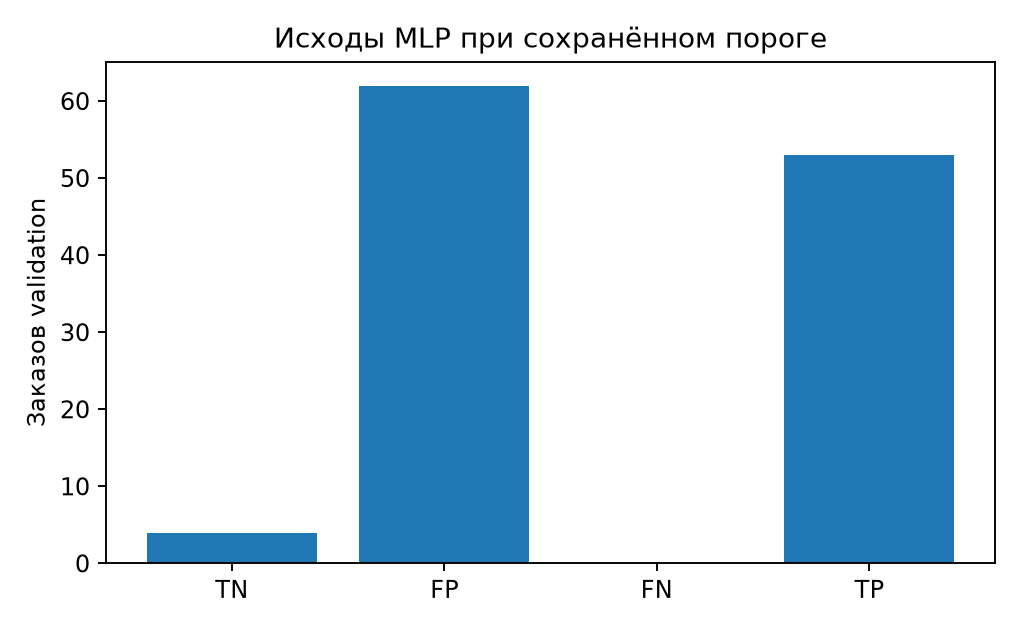

In [4]:
v=pd.read_csv(R/'validation_predictions.csv')
assert len(v)==manifest['splits']['validation'] and set(v.order_id)==set(parts['validation'].order_id)
tau=float(config['threshold']);pred=(v.p_mlp>=tau).astype(int)
tn,fp,fn,tp=confusion_matrix(v.late,pred,labels=[0,1]).ravel()
metrics={'AP':average_precision_score(v.late,v.p_mlp),'Brier':brier_score_loss(v.late,v.p_mlp),
 'Precision':precision_score(v.late,pred,zero_division=0),'Recall':recall_score(v.late,pred,zero_division=0),
 'F1':f1_score(v.late,pred,zero_division=0),'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
 'alerts':int(pred.sum()),'alert_rate':float(pred.mean()),'cost_total_rub':int(60*fp+300*fn),
 'cost_100_rub':float(100*(60*fp+300*fn)/len(v))}
saved=pd.read_csv(R/'validation_model_comparison.csv').set_index('model').loc['MLP_selected']
for key,saved_key in [('AP','AP'),('Brier','Brier'),('Precision','precision'),('Recall','recall'),('F1','F1'),
 ('FP','FP'),('FN','FN'),('cost_100_rub','cost_per_100_rub'),('alert_rate','alert_share')]:
    assert np.isclose(metrics[key],saved[saved_key],atol=1e-8),f'Расхождение {key}'
assert metrics['TN']+metrics['FP']+metrics['FN']+metrics['TP']==len(v)
display(pd.DataFrame([metrics]).T.rename(columns={0:'validation'}))
pd.DataFrame([metrics]).to_csv(OUT/'validation_recalculated.csv',index=False)
print('Стоимость: 60·FP + 300·FN =',metrics['cost_total_rub'],'₽; цены учебные, не тариф предприятия')

capacity_per_100=20
k=int(np.floor(capacity_per_100/100*len(v)))
top=np.zeros(len(v),dtype=int)
top[np.argsort(-v.p_mlp.to_numpy(),kind='stable')[:k]]=1
tn_k,fp_k,fn_k,tp_k=confusion_matrix(v.late,top,labels=[0,1]).ravel()
capacity_table=pd.DataFrame([
 {'сценарий':'порог lb21 — действующее учебное правило','сигналов':metrics['alerts'],
  'сигналов_на_100':100*metrics['alert_rate'],'FP':metrics['FP'],'FN':metrics['FN'],
  'стоимость_на_100_руб':metrics['cost_100_rub']},
 {'сценарий':'гипотеза top-k при вместимости 20/100','сигналов':int(top.sum()),
  'сигналов_на_100':100*top.mean(),'FP':int(fp_k),'FN':int(fn_k),
  'стоимость_на_100_руб':100*(60*fp_k+300*fn_k)/len(v)}])
display(capacity_table)
capacity_table.to_csv(OUT/'capacity_scenario.csv',index=False)
print('Гипотетический лимит превышен на',round(100*metrics['alert_rate']-20,2),'сигнала на 100 заказов.')
print('Возможный регламент: очередь топ-рисков для диспетчера, ручная проверка, фиксация необработанных сигналов; новый top-k требует отдельного согласования и проверки эффекта.')
fig,ax=plt.subplots(figsize=(6,3.7))
ax.bar(['TN','FP','FN','TP'],[tn,fp,fn,tp]);ax.set(ylabel='Заказов validation',title='Исходы MLP при сохранённом пороге')
fig.tight_layout();fig.savefig('predefense_confusion.png',dpi=170);plt.close(fig)
display(Image(filename='predefense_confusion.png'))

## 5. Решение о готовности (56–75 мин)

Технические `assert` подтверждают лишь узкую часть требований. Сделайте отдельный аудит готовности к внедрению: данные, мониторинг, человек в контуре, производительность, отказоустойчивость, дрейф, безопасность и ответственность. Для каждого пункта укажите **доказательство**, статус и действие. Пустое доказательство = статус не пройден, даже если модель показала хороший AP.

In [5]:
readiness_items=[
 ('Данные','Происхождение учебного набора и контрольная сумма','доказано','manifest SHA-256 совпал с orders_dirty.csv','владелец данных','архивировать паспорт источника','2026-12-01'),
 ('Данные','Права на использование реальных заказов','не подтверждено','договор, разрешение и политика хранения не представлены','владелец данных','получить документы о правах и сроках хранения','2026-12-08'),
 ('Данные','Доступность всех пяти X в момент оформления','частично','словарь говорит «при создании», журнал событий процесса не проверен','аналитик данных','сверить время появления полей с журналом заказов','2026-12-08'),
 ('Данные','Репрезентативность реальных сезонов и зон','не подтверждено','учебный набор 598 заказов, нет независимых реальных периодов','аналитик данных','собрать новый период и сравнить распределения','2026-12-15'),
 ('Модель','Разделение по времени и непересечение ID','доказано','split_membership.csv и автоматические assert','аналитик ML','сохранить проверки в протоколе обновления','2026-12-01'),
 ('Модель','Воспроизводимый инференс','доказано',f'12 объектов, Δmax={maxerr:.2e}<1e-5','инженер ML','закрепить версии окружения и регрессионный тест','2026-12-01'),
 ('Модель','Независимая окончательная оценка','не подтверждено','test ранее оценивался в lb20, в lb22 не открывался','аналитик ML','получить новый будущий holdout и заморозить протокол','2026-12-15'),
 ('Качество','Калибровка вероятностей и цены FP/FN','не подтверждено','60/300 ₽ — условный сценарий; калибровка не проверена','владелец продукта','проверить калибровку и согласовать реальные потери','2026-12-15'),
 ('Качество','Качество по зонам, погоде и сезонам','не подтверждено','slice-отчёта на реальных данных нет','аналитик ML','посчитать AP, Recall и FP/FN по группам','2026-12-15'),
 ('Инфраструктура','p95 задержки и пиковая нагрузка','не подтверждено','замеры на целевой инфраструктуре не проводились','инженер MLOps','провести нагрузочное испытание и установить SLO','2026-12-22'),
 ('Инфраструктура','Мониторинг, версионирование и откат','не подтверждено','нет дашборда, алертов и процедуры rollback','инженер MLOps','настроить мониторинг входов, ошибок, версии и откат','2026-12-22'),
 ('Операции','Вместимость диспетчера и действия по сигналу','не подтверждено',f'{metrics["alert_rate"]*100:.1f} сигнала/100 при условном лимите 20','руководитель диспетчеров','согласовать очередь, приоритеты и ручной разбор','2026-12-15'),
 ('Безопасность','Персональные данные, доступ и аудит','не подтверждено','правовой и технический аудит доступа не представлен','специалист ИБ','оценить идентификаторы и утвердить разграничение доступа','2026-12-22'),
 ('Люди','Ответственность и остановка автоматизации','не подтверждено','нет утверждённого регламента принятия/отмены решения','владелец продукта','назначить ответственных и утвердить human-in-the-loop','2026-12-22')]
readiness=pd.DataFrame(readiness_items,columns=['блок','критерий','статус','доказательство','предлагаемый владелец','план','плановый срок'])
allowed={'доказано','частично','не подтверждено','неприменимо'}
assert set(readiness.статус)<=allowed
assert readiness[['доказательство','предлагаемый владелец','план','плановый срок']].notna().all().all()
readiness.to_csv(OUT/'deployment_readiness.csv',index=False,encoding='utf-8-sig')
display(readiness[['блок','критерий','статус','доказательство','предлагаемый владелец','плановый срок']])
print('Вердикт: учебная техническая предзащита — да; продуктивный запуск — NO-GO. Сроки и владельцы в таблице предложены, не утверждены организацией.')

,блок,критерий,статус,доказательство,предлагаемый владелец,плановый срок
0,Данные,Происхождение учебного набора и контрольная сумма,доказано,manifest SHA-256 совпал с orders_dirty.csv,владелец данных,2026-12-01
1,Данные,Права на использование реальных заказов,не подтверждено,"договор, разрешение и политика хранения не пре...",владелец данных,2026-12-08
2,Данные,Доступность всех пяти X в момент оформления,частично,"словарь говорит «при создании», журнал событий...",аналитик данных,2026-12-08
3,Данные,Репрезентативность реальных сезонов и зон,не подтверждено,"учебный набор 598 заказов, нет независимых реа...",аналитик данных,2026-12-15
4,Модель,Разделение по времени и непересечение ID,доказано,split_membership.csv и автоматические assert,аналитик ML,2026-12-01
5,Модель,Воспроизводимый инференс,доказано,"12 объектов, Δmax=2.55e-08<1e-5",инженер ML,2026-12-01
6,Модель,Независимая окончательная оценка,не подтверждено,"test ранее оценивался в lb20, в lb22 не открыв...",аналитик ML,2026-12-15
7,Качество,Калибровка вероятностей и цены FP/FN,не подтверждено,60/300 ₽ — условный сценарий; калибровка не пр...,владелец продукта,2026-12-15
8,Качество,"Качество по зонам, погоде и сезонам",не подтверждено,slice-отчёта на реальных данных нет,аналитик ML,2026-12-15
9,Инфраструктура,p95 задержки и пиковая нагрузка,не подтверждено,замеры на целевой инфраструктуре не проводились,инженер MLOps,2026-12-22


Вердикт: учебная техническая предзащита — да; продуктивный запуск — NO-GO. Сроки и владельцы в таблице предложены, не утверждены организацией.


## 6. Карточка модели и пяти-минутная предзащита (75–90 мин)

**Структура доклада:** (0:00–0:45) задача и момент прогноза; (0:45–1:30) данные и split; (1:30–2:30) baseline vs MLP и статистика seed; (2:30–3:30) потери/стоимость/ограничения; (3:30–4:30) восстановление инференса; (4:30–5:00) решение комиссии и план.

**Вопросы комиссии:** почему сеть, а не логистическая регрессия; что запрещено в `X`; почему `test` не должен участвовать в выборе; почему AP не равен F1; как обнаружить дрейф; кто принимает решение по сигналу; что потребуется до запуска на предприятии.

In [6]:
exp=pd.read_csv(R/'experiments.csv')
base=pd.read_csv(R/'validation_model_comparison.csv').set_index('model')
best_epoch=int(exp.loc[exp.model.eq(manifest['selected_model'])&exp.seed.eq(config['seed']),'best_epoch'].iloc[0])
model_card=f'''# Model Card — учебный прототип, практика 22

## Назначение и граница прогноза
Оценка задержки более чем на 15 минут в момент оформления заказа. Выход — вероятность и сигнал диспетчеру при пороге {tau:.2f}; автоматического решения без человека нет.

## Данные и права
Источник: {manifest['origin']}. Исходно {len(raw)} строк; после удаления {full_duplicates} дубля и {conflict_count} конфликтной метки — {len(clean)} заказов. SHA-256: {source_sha}. Права на реальные данные и эксплуатационное использование не подтверждены. Данные учебные и не доказывают переносимость на действующую службу доставки.

## Входной контракт
Порядок полей: {', '.join(FEATURES)}. Числа: {', '.join(numeric)}; категории: {', '.join(categorical)}. Запрещены как X: {', '.join(FORBIDDEN)}. Неизвестные погода или зона кодируются one-hot без аварии, но требуют ручной проверки; лишнее поле city, отсутствующая колонка, текстовое расстояние и distance_km>100 отклоняются учебной проверкой схемы. Порог 100 км — диагностический пример, не утверждённый бизнес-лимит.

## Обучение и восстановление
Хронологическое разделение train={len(parts['train'])}, validation={len(parts['validation'])}, test={len(parts['test'])}; test совпадает с ранее оценённой частью lb20 и здесь не оценивался. Препроцессор fit только train. MLP {config['n_inputs']}→{config['width']}→{config['width']}→1, ReLU, dropout={config['dropout']}, AdamW, BCEWithLogitsLoss, seed={config['seed']}, лучшая эпоха {best_epoch}. Файлы: preprocessor.joblib, mlp_state.pt, model_config.json, manifest.json. Версии обучения из manifest: Python {manifest['python']}, PyTorch {manifest['torch']}, NumPy {manifest['numpy']}, pandas {manifest['pandas']}, scikit-learn {manifest['sklearn']}; текущие версии вывел notebook. Собственный joblib проверен по происхождению; сторонние pickle/joblib не загружать.

## Validation качество и условная стоимость
N={len(v)}, положительных {int(v.late.sum())}; AP={metrics['AP']:.4f}, Brier={metrics['Brier']:.4f}, Precision={metrics['Precision']:.4f}, Recall={metrics['Recall']:.4f}, F1={metrics['F1']:.4f}. TN={metrics['TN']}, FP={metrics['FP']}, FN={metrics['FN']}, TP={metrics['TP']}. Сигналов {metrics['alerts']} ({metrics['alert_rate']*100:.1f}/100); условная стоимость {metrics['cost_100_rub']:.2f} ₽/100 при 60 ₽/FP и 300 ₽/FN. Для сравнения AP: Dummy={base.loc['Dummy','AP']:.4f}, LogReg={base.loc['LogReg','AP']:.4f}, Boosting={base.loc['Boosting','AP']:.4f}; учебная стоимость LogReg {base.loc['LogReg','cost_per_100_rub']:.2f} ₽/100. Это validation, не окончательный независимый test.

## Инвариант воспроизводимости
На {len(samples)} фиксированных объектах Δmax={maxerr:.2e}<1e-5. Совпадение проверяет техническое восстановление, не эффективность на новых заказах.

## Пропускная способность и область применения
Условный лимит 20 сигналов/100 нарушен: {metrics['alert_rate']*100:.1f}/100. Сценарий top-k показан отдельно и не заменяет сохранённый порог без согласования. Использование допускается только как учебная демонстрация с человеком в контуре. Не использовать для автоматического назначения курьеров или обещаний клиентам.

## Безопасность, мониторинг и ответственность
Права, персональные/связуемые идентификаторы, хранение и доступ не проверены. Нет испытаний по зонам/сезонам, калибровки на реальных данных, p95 latency, мониторинга дрейфа, регламента отката и назначенного ответственного диспетчера. Эти пункты отражены в deployment_readiness.csv с предлагаемыми ролями и плановыми сроками.

## Решение
GO для учебной предзащиты технического прототипа; NO-GO для продуктивного запуска. Условия пересмотра: новый независимый период, подтверждённая экономическая модель, права и безопасность, нагрузочные испытания, мониторинг и human-in-the-loop.
'''
(OUT/'model_card.md').write_text(model_card,encoding='utf-8')
(OUT/'predefense_confusion.png').write_bytes(Path('predefense_confusion.png').read_bytes())

speech=f'''# Предзащита учебного ML-проекта — план на 5 минут

## 0:00–0:45 Задача и момент прогноза
Предлагаю учебный прототип сигнала диспетчеру о риске опоздания заказа более чем на 15 минут. Сигнал нужен в момент оформления, когда ещё можно скорректировать работу. Это рекомендация человеку, а не автоматическое решение. Целевая метка известна только после доставки, поэтому фактическое время не может быть входом модели.

## 0:45–1:30 Данные и границы
Мы использовали собственный архив занятия 21 на orders_dirty.csv, а не демонстрационный пакет. Исходно 600 строк, после удаления дубля и конфликтной метки — 598. Хронологические части: train 358, validation {len(v)}, test 121. Из словаря выбраны пять признаков, доступных при создании заказа; actual_minutes, late, ID и сырая дата исключены из X. Контрольная сумма исходника и непересечение ID проверены. Тестовая часть уже оценивалась в занятии 20, поэтому новой независимой проверки здесь нет.

## 1:30–2:30 Модели, метрики и цена
В занятии 21 сравнили девять запусков MLP при трёх seed и три простые модели. Регуляризованная 16–16 выбрана по среднему AP, checkpoint seed {config['seed']} — по validation BCE. Сейчас из сохранённых прогнозов пересчитаны AP {metrics['AP']:.4f}, Brier {metrics['Brier']:.4f}, F1 {metrics['F1']:.4f}; они совпали с архивом. При пороге {tau:.2f} получено FP={metrics['FP']} и FN={metrics['FN']}; условная цена {metrics['cost_100_rub']:.0f} рублей на 100 заказов. LogisticRegression на той же validation имеет AP {base.loc['LogReg','AP']:.4f} и меньшую условную цену {base.loc['LogReg','cost_per_100_rub']:.0f} рублей. Поэтому MLP не доказала практического преимущества.

## 2:30–3:30 Ограничения и человеческое действие
При выбранном пороге тревога возникла для {metrics['alerts']} из {len(v)} заказов, или {metrics['alert_rate']*100:.1f} на 100. Гипотетический лимит 20 сигналов на 100 не выполняется. Диспетчеру потребуется согласованная очередь приоритетов, ручная проверка и журнал необработанных сигналов. Пересчёт top-k показан как сценарий, но это уже другой регламент, который нельзя объявлять внедрённым. Цены 60 и 300 рублей учебные. Реальная выгода, сезонная устойчивость, калибровка и права на данные не подтверждены.

## 3:30–4:30 Повторное восстановление
Я загрузил собственный проверенный архив, конфигурацию, препроцессор и веса с weights_only=True. На {len(samples)} сохранённых объектах максимальное отклонение вероятности равно {maxerr:.2e}, меньше допуска 10⁻⁵. Я также проверил входную схему: пропущенная колонка и текстовое расстояние отклоняются; неизвестные погода и зона не вызывают сбоя one-hot, но требуют ручной проверки; лишнее поле city отклоняется. Это доказательство воспроизводимости инференса, а не доказательство качества на будущих заказах.

## 4:30–5:00 Вердикт и три приоритета
К учебной предзащите прототип готов, к продуктивному запуску — нет. Первое: владелец данных и аналитик ML должны получить права и новый независимый период с проверкой групп и калибровки. Второе: руководитель диспетчеров и владелец продукта должны подтвердить вместимость, реальные цены ошибок и человеческий регламент. Третье: инженер MLOps и специалист ИБ должны проверить p95, мониторинг, откат и защиту данных. Плановые сроки и доказательства перечислены в readiness matrix; без закрытия этих пунктов решение NO-GO сохраняется.

## Короткие ответы комиссии
- AP оценивает ранжирование вероятностей; F1 зависит от порога, поэтому они могут расходиться.
- Формула порога 60/(60+300)≈1/6 требует калиброванных вероятностей, постоянных затрат и отсутствия ограничений вместимости; здесь это не доказано.
- Один state_dict без архитектуры, схемы полей и обученного препроцессора не восстанавливает прогноз.
- Новый реальный период нужен, поскольку ранее просмотренный test не становится независимым от повторной оценки.
- Неизвестные weather/zone требуют мониторинга; поле city вне контракта, аномальное расстояние и отсутствующая колонка отклоняются до решения диспетчера.
'''
(OUT/'predefense_speech.md').write_text(speech,encoding='utf-8')
summary={'source':manifest['origin'],'bundle_sha256':hashlib.sha256(bundle.read_bytes()).hexdigest(),
 'inference_delta_max':maxerr,'validation_n':len(v),'validation_positive':int(v.late.sum()),
 'metrics':metrics,'prototype_predefense':'GO','production':'NO-GO','test_evaluated_in_lb22':False,
 'owners_and_deadlines_are_proposed':True}
(OUT/'predefense_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
print('Созданы:',sorted(q.name for q in OUT.iterdir()))
print('GO для учебной предзащиты; NO-GO для внедрения. В notebook отсутствует новая оценка test.')

Созданы: ['artifact_audit.csv', 'capacity_scenario.csv', 'deployment_readiness.csv', 'field_provenance.csv', 'inference_protocol.csv', 'model_card.md', 'predefense_confusion.png', 'predefense_speech.md', 'predefense_summary.json', 'schema_tests.csv', 'source_audit.csv', 'split_summary.csv', 'validation_recalculated.csv']
GO для учебной предзащиты; NO-GO для внедрения. В notebook отсутствует новая оценка test.


### Что сдавать

`22_student.ipynb`, заполненную `deployment_readiness.csv`, `model_card.md`, `predefense_speech.md`, снимок/протокол демонстрации восстановленной модели и итоговый отчёт 3–5 страниц. К защите должны быть доступны артефакты 21, таблицы экспериментов и численно проверяемые выводы.  
**Критерий зачёта:** все ограничения честно отражены; неподтверждённые эксплуатационные критерии не отмечены как выполненные.